# Algoritmo Mean Shift: casos reais de alarmes

Três agrupamentos com históricos reais de alarmes. Em cada caso, cada tag vira um ponto descrito por duas características, e o Mean Shift é aplicado sobre esses pontos.

Adicione os arquivos `case-b-dea.csv` (refino) e `case-a-gasoduto.csv` (gasoduto), com colunas `tag`, `inicio`, `reconhecimento`, `fim`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import MeanShift
from sklearn.preprocessing import StandardScaler


def escolher_h(X):
    # Aplica o Mean Shift para varios h e escolhe o h do meio do maior trecho com o mesmo nº de clusters (> 1)
    valores_h = np.round(np.arange(0.2, 2.51, 0.1), 2)
    n_clusters = [len(MeanShift(bandwidth=h, bin_seeding=True).fit(X).cluster_centers_) for h in valores_h]

    trechos = pd.DataFrame({'h': valores_h, 'n': n_clusters})
    trechos['trecho'] = (trechos['n'] != trechos['n'].shift()).cumsum()
    estaveis = trechos[trechos['n'] > 1].groupby('trecho')['h']
    valores = estaveis.get_group(estaveis.size().idxmax()).values
    h = valores[len(valores) // 2]

    plt.figure(figsize=(6, 3.5))
    plt.step(valores_h, n_clusters, where='mid')
    plt.axvline(h, linestyle='--', color='black')
    plt.xlabel('bandwidth (h)')
    plt.ylabel('Nº de clusters')
    plt.title(f'Número de clusters em função de bandwidth (h = {h})')
    plt.show()
    return h


def resumo_clusters(tags, alarmes):
    # Nº de tags e participacao de cada cluster no total de ativacoes
    linhas = []
    for k in sorted(tags['cluster'].unique()):
        tags_k = tags.index[tags['cluster'] == k]
        linhas.append({'cluster': k, 'tags': len(tags_k),
                       'pct_ativacoes': round(alarmes['tag'].isin(tags_k).mean() * 100, 1)})
    return pd.DataFrame(linhas).set_index('cluster')

## Dados do refino (casos 1 e 2)

In [2]:
# Carregamento do historico do refino e recorte de 4 semanas
refino = pd.read_csv('case-b-dea.csv', parse_dates=['inicio', 'reconhecimento', 'fim']).drop_duplicates()

DIAS = 28 # Amostra de dados em dias
refino = refino[(refino['inicio'] >= '2025-01-06') & (refino['inicio'] < '2025-02-03')].copy()

# Duracao e tempo ate o reconhecimento (TTA) de cada ocorrencia
refino['duracao_s'] = (refino['fim'] - refino['inicio']).dt.total_seconds()
refino['tta_s'] = (refino['reconhecimento'] - refino['inicio']).dt.total_seconds()

# Agregacao por tag
tags_refino = refino.groupby('tag').agg(
    ativacoes=('inicio', 'size'),
    duracao_mediana_s=('duracao_s', 'median'),
    tta_mediano_s=('tta_s', 'median'),
)
tags_refino['ativacoes_dia'] = tags_refino['ativacoes'] / DIAS
tags_refino = tags_refino[tags_refino['ativacoes'] >= 5] # Filtro: apenas tags com 5 ou mais ativacoes

print(f'{len(refino):,} ativações, {len(tags_refino)} tags')
tags_refino.describe().round(2)

167,010 ativações, 848 tags


,ativacoes,duracao_mediana_s,tta_mediano_s,ativacoes_dia
count,848.00,844.00,845.00,848.00
mean,195.32,17978.99,6086.67,6.98
std,2431.86,119891.75,37429.14,86.85
min,5.00,1.00,0.00,0.18
25%,9.00,24.00,16.00,0.32
50%,19.00,297.25,24.00,0.68
75%,51.00,4627.88,71.00,1.82
max,56391.00,3226791.00,457546.00,2013.96


## Caso 1: ativações por dia × duração mediana

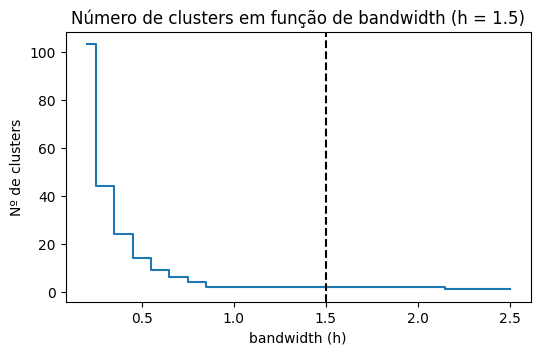

In [3]:
tags = tags_refino.dropna(subset=['duracao_mediana_s']).copy()

# Escala log nas duas caracteristicas (duracao de 0 s vira 1 s) e padronizacao
eixos = pd.DataFrame({
    'ativacoes_dia': np.log10(tags['ativacoes_dia']),
    'duracao_mediana_s': np.log10(tags['duracao_mediana_s'].clip(lower=1)),
})
escala = StandardScaler().fit(eixos)
X = escala.transform(eixos)

h = escolher_h(X)

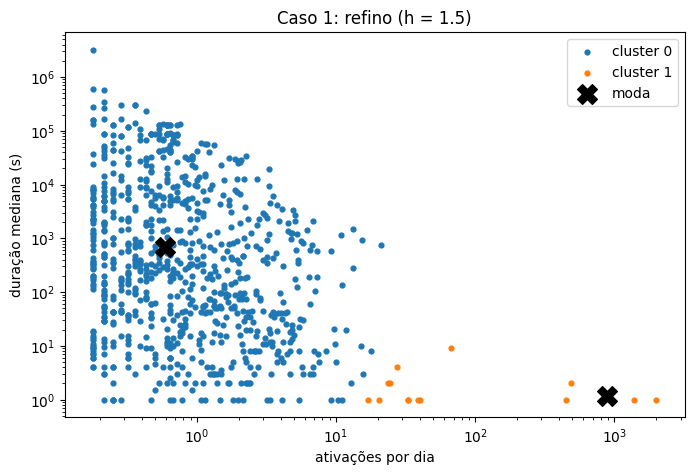

,tags,pct_ativacoes
cluster,,
0,830,20.9
1,14,78.2


In [4]:
modelo = MeanShift(bandwidth=h, bin_seeding=True).fit(X)
tags['cluster'] = modelo.labels_

# Centros (modas) de volta para as unidades originais
centros = 10 ** escala.inverse_transform(modelo.cluster_centers_)

plt.figure(figsize=(8, 5))
for k in sorted(tags['cluster'].unique()):
    pontos = tags[tags['cluster'] == k]
    plt.scatter(pontos['ativacoes_dia'], pontos['duracao_mediana_s'].clip(lower=1), s=12, label=f'cluster {k}')
plt.scatter(centros[:, 0], centros[:, 1], marker='X', s=200, color='black', label='moda')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('ativações por dia')
plt.ylabel('duração mediana (s)')
plt.title(f'Caso 1: refino (h = {h})')
plt.legend()
plt.show()

resumo_clusters(tags, refino)

## Caso 2: duração mediana × tempo até reconhecer

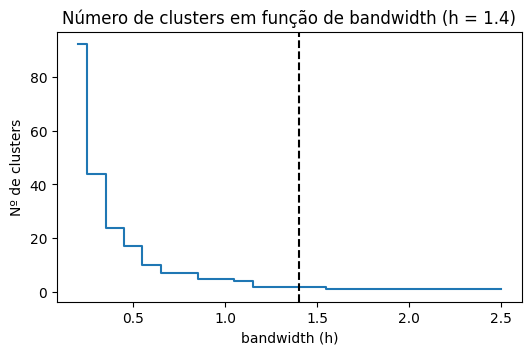

In [5]:
tags = tags_refino.dropna(subset=['duracao_mediana_s', 'tta_mediano_s']).copy()

# Escala log (valores de 0 s viram 1 s) e padronizacao
eixos = np.log10(tags[['duracao_mediana_s', 'tta_mediano_s']].clip(lower=1))
escala = StandardScaler().fit(eixos)
X = escala.transform(eixos)

h = escolher_h(X)

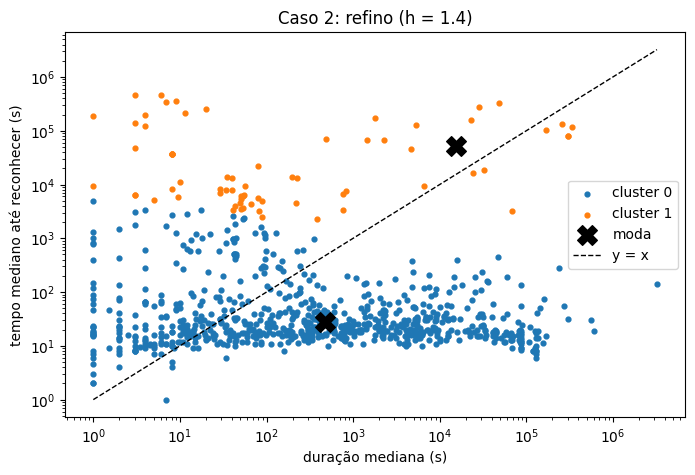

,tags,pct_ativacoes
cluster,,
0,772,97.0
1,69,1.7


In [6]:
modelo = MeanShift(bandwidth=h, bin_seeding=True).fit(X)
tags['cluster'] = modelo.labels_
centros = 10 ** escala.inverse_transform(modelo.cluster_centers_)

plt.figure(figsize=(8, 5))
for k in sorted(tags['cluster'].unique()):
    pontos = tags[tags['cluster'] == k].clip(lower=1)
    plt.scatter(pontos['duracao_mediana_s'], pontos['tta_mediano_s'], s=12, label=f'cluster {k}')
plt.scatter(centros[:, 0], centros[:, 1], marker='X', s=200, color='black', label='moda')

# Diagonal y = x: acima dela, o alarme normaliza antes de ser reconhecido
limite = [1, tags[['duracao_mediana_s', 'tta_mediano_s']].max().max()]
plt.plot(limite, limite, 'k--', linewidth=1, label='y = x')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('duração mediana (s)')
plt.ylabel('tempo mediano até reconhecer (s)')
plt.title(f'Caso 2: refino (h = {h})')
plt.legend()
plt.show()

resumo_clusters(tags, refino)

## Caso 3: % reconhecidas × % normalizadas (gasoduto)

6,537 ativações, 256 tags


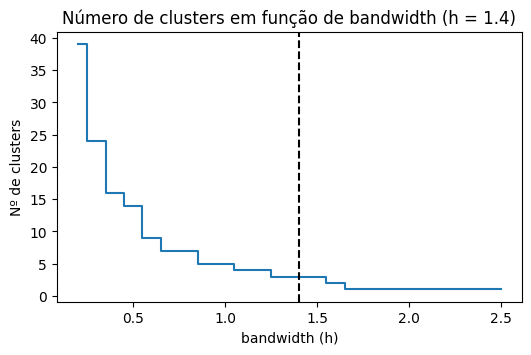

In [7]:
# Carregamento do historico do gasoduto (13 dias)
gasoduto = pd.read_csv('case-a-gasoduto.csv', parse_dates=['inicio', 'reconhecimento', 'fim']).drop_duplicates()

# Fracao das ativacoes de cada tag que foram reconhecidas e que normalizaram
tags = gasoduto.groupby('tag').agg(
    ativacoes=('inicio', 'size'),
    pct_reconhecidas=('reconhecimento', lambda s: s.notna().mean()),
    pct_normalizadas=('fim', lambda s: s.notna().mean()),
)
tags = tags[tags['ativacoes'] >= 5]

# Escala logit para fracoes entre 0 e 1 (limitadas a 1% e 99%) e padronizacao
fracoes = tags[['pct_reconhecidas', 'pct_normalizadas']].clip(0.01, 0.99)
eixos = np.log(fracoes / (1 - fracoes))
escala = StandardScaler().fit(eixos)
X = escala.transform(eixos)

print(f'{len(gasoduto):,} ativações, {len(tags)} tags')
h = escolher_h(X)

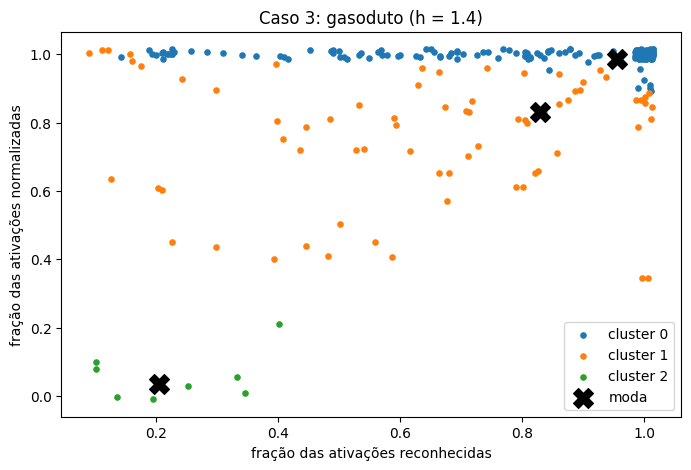

,tags,pct_ativacoes
cluster,,
0,176,32.8
1,72,26.4
2,8,2.1


In [8]:
modelo = MeanShift(bandwidth=h, bin_seeding=True).fit(X)
tags['cluster'] = modelo.labels_

# Centros de volta para fracoes (inversa do logit)
centros = 1 / (1 + np.exp(-escala.inverse_transform(modelo.cluster_centers_)))

# Pequeno deslocamento aleatorio so no grafico, para separar pontos sobrepostos
ruido = np.random.default_rng(0).uniform(-0.015, 0.015, size=(len(tags), 2))

plt.figure(figsize=(8, 5))
for k in sorted(tags['cluster'].unique()):
    i = (tags['cluster'] == k).values
    plt.scatter(tags['pct_reconhecidas'][i] + ruido[i, 0], tags['pct_normalizadas'][i] + ruido[i, 1],
                s=14, label=f'cluster {k}')
plt.scatter(centros[:, 0], centros[:, 1], marker='X', s=200, color='black', label='moda')
plt.xlabel('fração das ativações reconhecidas')
plt.ylabel('fração das ativações normalizadas')
plt.title(f'Caso 3: gasoduto (h = {h})')
plt.legend()
plt.show()

resumo_clusters(tags, gasoduto)